# Аудит семи направлений поиска карманов

49 731 точка, 3 961 матч, 3 628 пригодных финалов. Срез исходников 25.10.2026 22:38 МСК. 42 468 правил/политик, 37 864 различных набора входов.

92 варианта прошли три временные части; 83 сохранились после дополнительных диагностик, представлены 32 группами. **После поправки на перебор статистически подтверждённых преимуществ нет.** Период 24–25 октября уже просматривался и не является независимым будущим тестом.

## Контекст и метод

Все сохранённые валидные основные FT-линии обеих сторон, включая наблюдения вне топ-5. Первый подходящий вход на матч и правило; задержки ≥3/≥5 минут проверяются по реально следующей котировке с тем же счётом и повторной проверкой условий. Asian-четверти и возвраты учитываются отдельно.

Ранняя часть: до 22 октября МСК; средняя: 22–23 октября; поздняя: 24–25 октября. Матч целиком относится к одной части. Финалы, ещё не известные к границе обучения, исключены из соответствующего обучения. Точные условия находятся в protocol.json и исходном отчёте Markdown.

Отсутствие данных о стадии кубка и подтверждённых финалов для старого архива соседних линий означает ограничение аудита, а не нулевую доходность.

In [1]:
import json, gzip
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
summary = json.loads((ROOT/'summary.json').read_text())
checks = json.loads((ROOT/'validation.json').read_text())
families = json.loads((ROOT/'family_results.json').read_text())
short = json.loads((ROOT/'shortlist.json').read_text())
print('Проверок:', sum(summary['evaluated_rules'].values()))
print('Различных наборов входов:', summary['unique_entry_selections'])
print('После диагностики:', checks['concentration_freshness_pass'])
print('Представителей:', checks['representative_count'])
assert summary['statistical_pass'] == 0


Проверок: 42468
Различных наборов входов: 37864
После диагностики: 83
Представителей: 32


## Результаты по направлениям

In [2]:
table = pd.DataFrame([{'Направление':r['name'], 'Проверок':r['evaluated_rules'],
                       'Три части +':r['stable_variants'],
                       'После диагностики':r['additional_diagnostic_pass']} for r in families])
print(table.to_string(index=False))
print('Соседние линии: финансовый расчёт невозможен без пригодных финалов.')


                       Направление  Проверок  Три части +  После диагностики
                   Лига и сценарий      9310            0                  0
        Прематчевый фаворит и счёт      9246            2                  2
Реакция на замеченный гол/удаление      5928           31                 30
                     История счёта      3836           11                 10
                    Прематч → live      8202           26                 22
                  Тип соревнования      5946           22                 19
                   Соседние тоталы         0            0                  0
Соседние линии: финансовый расчёт невозможен без пригодных финалов.


## Восемь приоритетных кандидатов

Это отбор после просмотра результатов, а не новый тест. Номера соответствуют условиям в shortlist.json и основном отчёте.

In [3]:
table = pd.DataFrame([{'№':i+1, 'N':r['total']['n'],
    'Ранний ROI %':round(100*r['folds'][0]['roi'],2),
    'Средний ROI %':round(100*r['folds'][1]['roi'],2),
    'Поздний ROI %':round(100*r['folds'][2]['roi'],2),
    'Поздний без 3 %':round(100*r['folds'][2]['without_top3'],2),
    'Поздний без лиги и 3 %':round(100*r['late_without_best_league']['without_top3'],2)} for i,r in enumerate(short)])
print(table.to_string(index=False))


 №   N  Ранний ROI %  Средний ROI %  Поздний ROI %  Поздний без 3 %  Поздний без лиги и 3 %
 1 259         15.35          14.47          14.44            12.42                   10.54
 2 217         26.30          15.83          14.98            12.59                   10.25
 3 323          9.36          11.60          17.40            15.70                   14.19
 4 309         12.68          12.57           8.88             7.21                    5.16
 5 252          7.91           7.23          17.85            15.83                   14.45
 6 359          5.29           6.23           9.01             7.45                    6.55
 7 842          2.75          10.60           4.92             4.21                    3.63
 8 208          8.95           7.80          12.97            10.46                    7.88


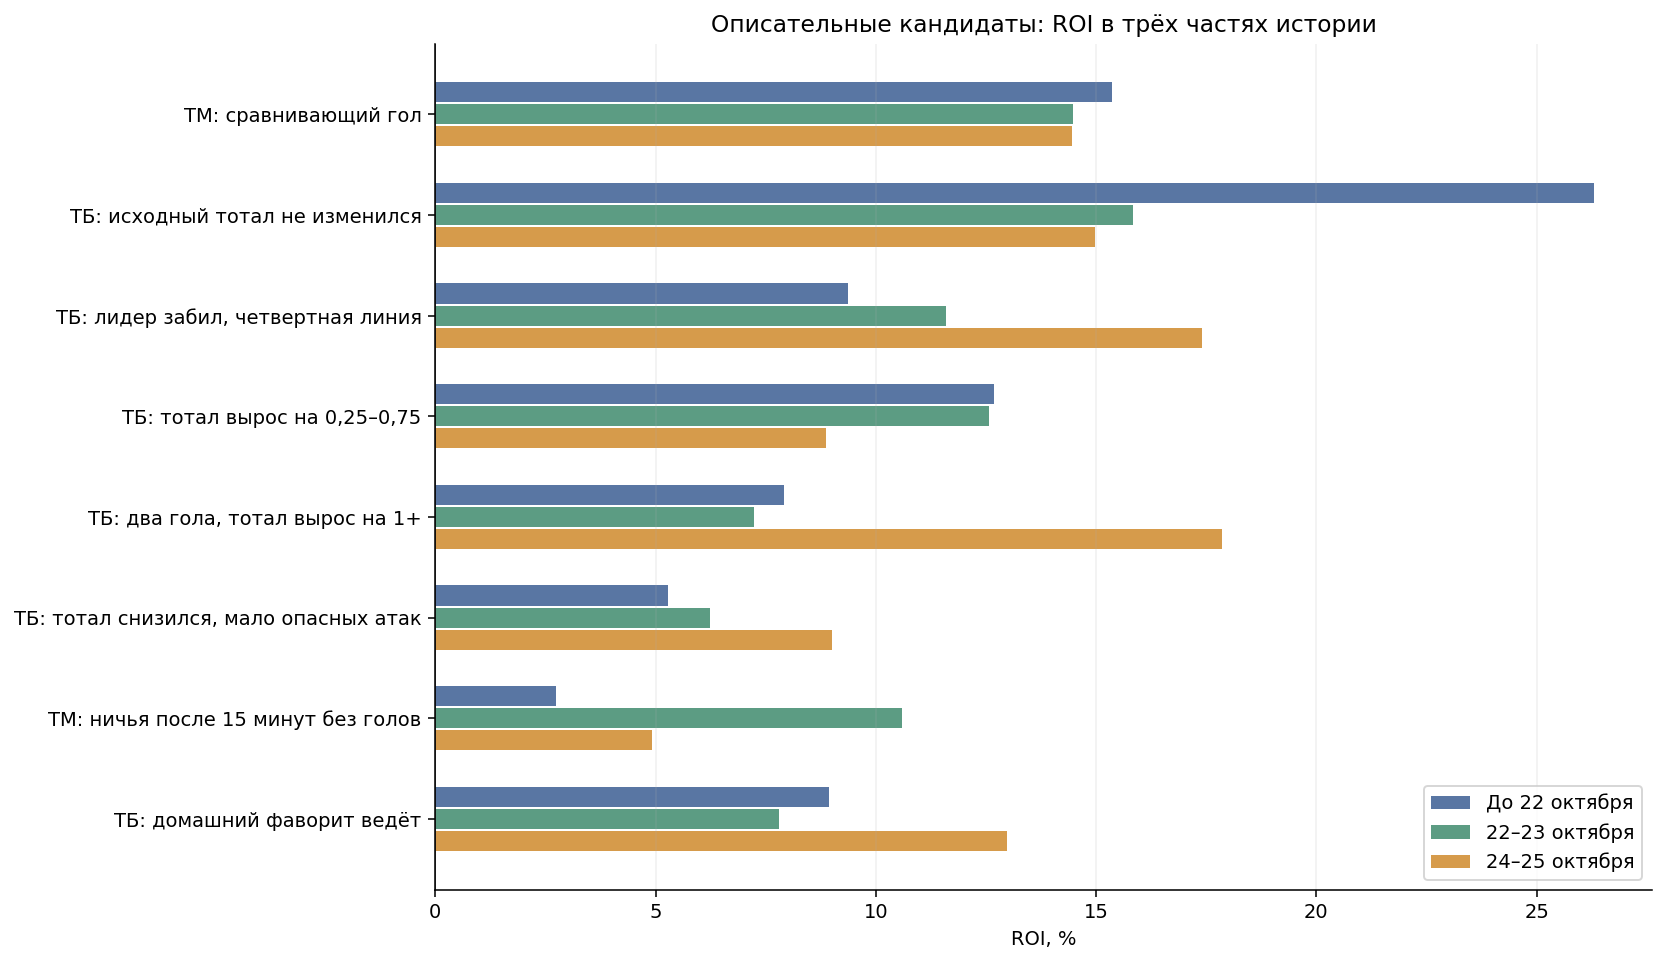

In [4]:
names=['ТМ: сравнивающий гол', 'ТБ: исходный тотал не изменился',
       'ТБ: лидер забил, четвертная линия', 'ТБ: тотал вырос на 0,25–0,75',
       'ТБ: два гола, тотал вырос на 1+', 'ТБ: тотал снизился, мало опасных атак',
       'ТМ: ничья после 15 минут без голов', 'ТБ: домашний фаворит ведёт']
fig, ax = plt.subplots(figsize=(12,7))
y=np.arange(len(short)); colors=['#5976a3','#5c9c83','#d69b4b']
for f, name in enumerate(['До 22 октября', '22–23 октября', '24–25 октября']):
    ax.barh(y+(f-1)*.22,[100*r['folds'][f]['roi'] for r in short],height=.20,label=name,color=colors[f])
ax.set_yticks(y,names); ax.invert_yaxis(); ax.axvline(0,color='#333333',lw=.8)
ax.set_xlabel('ROI, %'); ax.set_title('Описательные кандидаты: ROI в трёх частях истории')
ax.grid(axis='x',alpha=.18); ax.legend(loc='lower right'); fig.tight_layout()
plt.show()


## Независимая проверка расчёта

Входы представителей доступны в representative_ledger.json.gz с исходным путём и blob SHA. Проверка ниже заново считает четвертные исходы через Decimal и сверяет суммы с таблицей представителей.

In [5]:
from decimal import Decimal as D, ROUND_FLOOR
ledger=json.load(gzip.open(ROOT/'representative_ledger.json.gz'))
representatives=json.load(gzip.open(ROOT/'representatives.json.gz'))
totals={}; count=0
for r in ledger:
    if r['final'] is None: continue
    line=D(str(r['line'])); price=D(str(r['price'])); final=D(str(sum(r['final'])))
    low=(line*2).to_integral_value(rounding=ROUND_FLOOR)/2
    legs=[line] if line*2==(line*2).to_integral_value() else [low,low+D('.5')]
    result=sum(price-1 if (final>x if r['side']=='over' else final<x) else D(0) if final==x else D(-1) for x in legs)/len(legs)
    assert abs(float(result)-r['profit'])<1e-9
    count+=1
    if r['temporally_usable']:totals.setdefault(r['representative'],[]).append(float(result))
for i,r in enumerate(representatives,1):
    assert len(totals[i])==r['total']['n']
    assert abs(sum(totals[i])-r['total']['net'])<1e-8
print('Проверено сохранённых расчётов:',count)
print('Суммы и N всех представителей совпали.')


Проверено сохранённых расчётов: 12494
Суммы и N всех представителей совпали.


## Вывод

Наиболее интересны наблюдаемые реакции после гола и путь прематчевой линии к текущей. По отдельным лигам не получено устойчивых кандидатов; тип соревнования часто повторяет общий сценарий и не добавляет преимущества. Все найденные плюсы остаются ретроспективными. Действующие правила сбора и результаты не менялись.

Для полного воспроизведения исходной сетки: SCANNER_GIT_DIR указывает на клон Scaner, затем acquire.py → extract.py → derive.py → search.py → validate.py → report.py. Этот ноутбук проверяет сохранённую доказательную выборку и визуализирует результаты.